In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
occupancy_detection = fetch_ucirepo(id=357) 
  
# data (as pandas dataframes) 
X = occupancy_detection.data.features 
y = occupancy_detection.data.targets 
  
# metadata 
print(occupancy_detection.metadata) 
  
# variable information 
print(occupancy_detection.variables) 

{'uci_id': 357, 'name': 'Occupancy Detection ', 'repository_url': 'https://archive.ics.uci.edu/dataset/357/occupancy+detection', 'data_url': 'https://archive.ics.uci.edu/static/public/357/data.csv', 'abstract': 'Experimental data used for binary classification (room occupancy) from Temperature,Humidity,Light and CO2. Ground-truth occupancy was obtained from time stamped pictures that were taken every minute.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 20560, 'num_features': 6, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Occupancy'], 'index_col': ['id'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2016, 'last_updated': 'Sat Apr 13 2024', 'dataset_doi': '10.24432/C5X01N', 'creators': ['Luis Candanedo'], 'intro_paper': {'ID': 470, 'type': 'NATIVE', 'title': 'Accurate occupancy detection of an office room from light, temperature, humidity and CO2

#Section 1, dataset visualization through LDA and PCA

In [3]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Combine features and target into a single DataFrame
y_series = y.squeeze()                      
y_series.name = "class"
df = pd.concat([X, y_series], axis=1)

# Drop any records with missing values
print(f"Shape before dropna: {df.shape}")
print(f"Missing values per column:\n{df.isna().sum()[df.isna().sum() > 0]}")
df = df.dropna().reset_index(drop=True)
print(f"Shape after dropna:  {df.shape}")

# Class counts
print("\nClass counts:")
print(df["class"].value_counts())
print("\nClass proportions:")
print(df["class"].value_counts(normalize=True).round(3))

# Split back into features and (encoded) labels
X_clean = df.drop(columns="class")
le = LabelEncoder()
y_enc = le.fit_transform(df["class"])

print("\nLabel encoding:")
for i, name in enumerate(le.classes_):
    print(f"  {i} -> {name}")
print(f"\nX_clean: {X_clean.shape}, y_enc: {y_enc.shape}")

Shape before dropna: (20562, 7)
Missing values per column:
class    2
dtype: int64
Shape after dropna:  (20560, 7)

Class counts:
class
0.0    15810
1.0     4750
Name: count, dtype: int64

Class proportions:
class
0.0    0.769
1.0    0.231
Name: proportion, dtype: float64

Label encoding:
  0 -> 0.0
  1 -> 1.0

X_clean: (20560, 6), y_enc: (20560,)


Temperature      float64
Humidity         float64
Light            float64
CO2              float64
HumidityRatio    float64
hour             float64
day_of_week        int32
dtype: object
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
hour             0
day_of_week      0
dtype: int64


C:\Users\BenMi\AppData\Local\Temp\ipykernel_14844\380034015.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X_num["day_of_week"] = dt.dt.dayofweek           # 0 = Monday


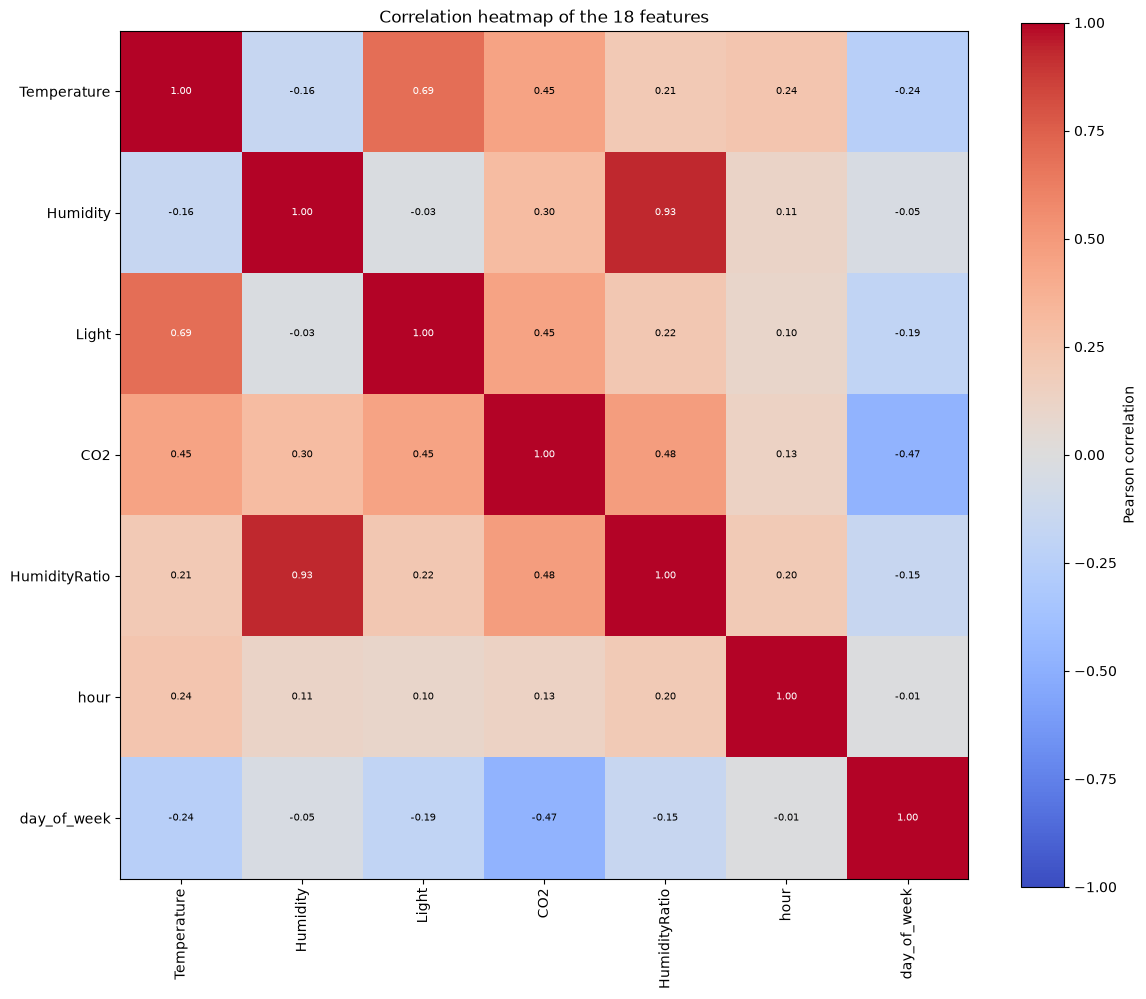

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Pearson correlation between all 18 features
X_num = X_clean.copy()

dt = pd.to_datetime(X_num["date"])
X_num["hour"] = dt.dt.hour + dt.dt.minute / 60   # time of day as a fraction
X_num["day_of_week"] = dt.dt.dayofweek           # 0 = Monday
X_num = X_num.drop(columns="date")

X_num = X_num.apply(pd.to_numeric, errors="coerce")

print(X_num.dtypes)       # all should now be float64 / int
print(X_num.isna().sum()) # should be all zeros

corr = X_num.corr()

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

# Axis labels
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)

# Write the correlation value in each cell
for i in range(len(corr)):
    for j in range(len(corr)):
        val = corr.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(val) > 0.6 else "black")

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation heatmap of the 18 features")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

PC1+PC2 explain 63.4% of variance
Components needed for 95% variance: 5


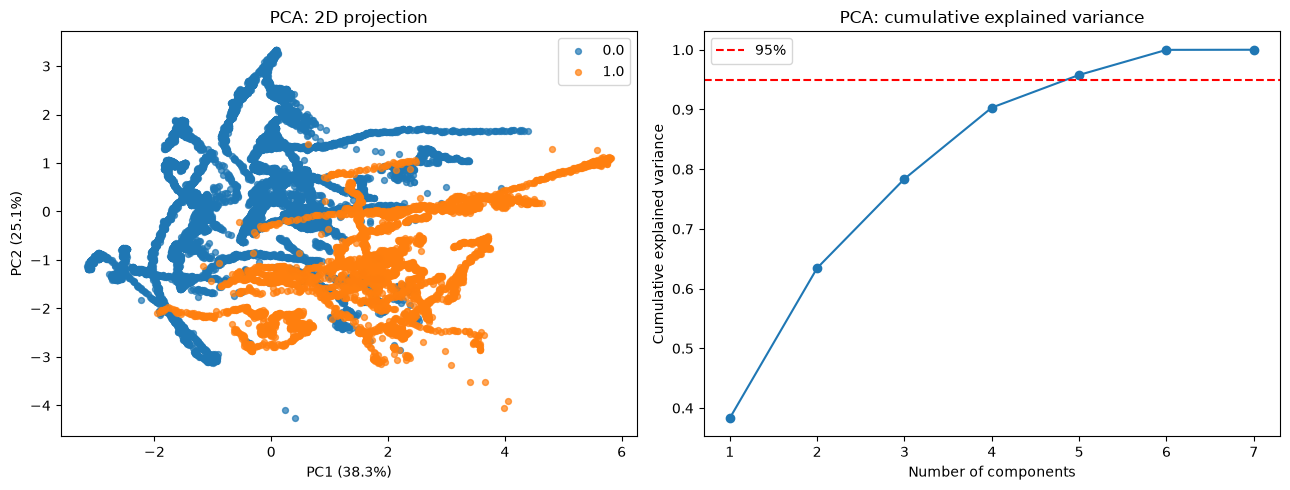

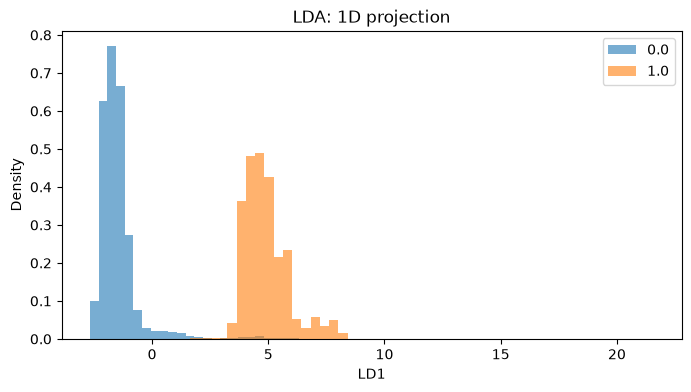

In [ ]:
#Using LDA and PCA to reduce the dimensionality of the dataset to 3 & 1 dimensions for visualization
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Standardise (for visualisation only; for modelling, scale inside a Pipeline)
X_scaled = StandardScaler().fit_transform(X_num)
SEED = 42

class_names = le.classes_
colors = plt.cm.tab10(np.arange(len(class_names)))

# ---------- PCA ----------
pca = PCA(n_components=X_scaled.shape[1], random_state=SEED)
X_pca_full = pca.fit_transform(X_scaled)
X_pca = X_pca_full[:, :2]

cum_var = np.cumsum(pca.explained_variance_ratio_)
print(f"PC1+PC2 explain {cum_var[1]*100:.1f}% of variance")
print(f"Components needed for 95% variance: {np.argmax(cum_var >= 0.95) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 2D PCA scatter
for i, name in enumerate(class_names):
    m = y_enc == i
    axes[0].scatter(X_pca[m, 0], X_pca[m, 1], s=18, alpha=0.7, color=colors[i], label=name)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[0].set_title("PCA: 2D projection")
axes[0].legend()

# Cumulative explained variance
axes[1].plot(range(1, len(cum_var) + 1), cum_var, marker="o")
axes[1].axhline(0.95, color="red", linestyle="--", label="95%")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_title("PCA: cumulative explained variance")
axes[1].legend()
plt.tight_layout()
plt.show()

# ---------- LDA (supervised projection) ----------
# With 2 classes, LDA can give at most 1 components (n_classes - 1)
lda = LinearDiscriminantAnalysis(n_components=1)
X_lda = lda.fit_transform(X_scaled, y_enc)

fig, ax = plt.subplots(figsize=(8, 4))
for i, name in enumerate(class_names):
    ax.hist(X_lda[y_enc == i, 0], bins=60, alpha=0.6, density=True,
            color=colors[i], label=name)
ax.set_xlabel("LD1")
ax.set_ylabel("Density")
ax.set_title("LDA: 1D projection")
ax.legend()
plt.show()


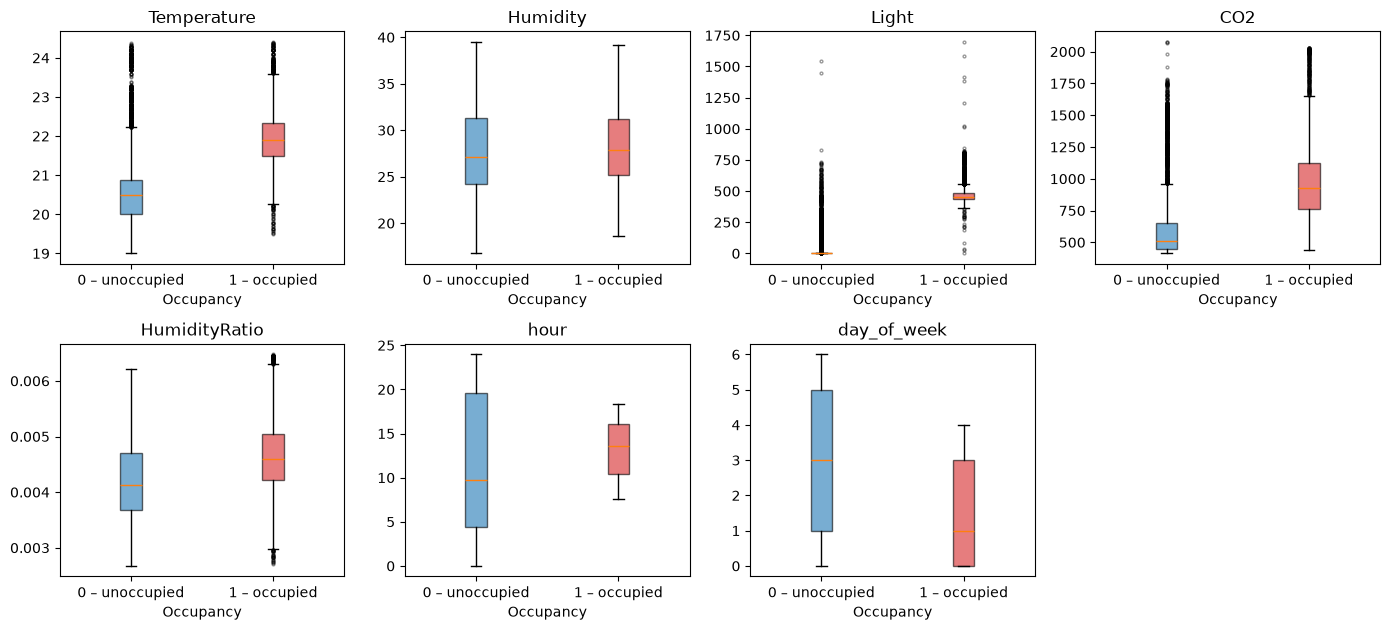

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Build the plotting dataframe: numeric features + occupancy label ---
features = list(X_num.columns)
df_plot = X_num.copy()
df_plot["Occupancy"] = np.ravel(y_enc)   # fixed: y_enc from LabelEncoder above (was y_clean)

order  = sorted(df_plot["Occupancy"].unique())          # [0.0, 1.0]
labels = {0.0: "0 – unoccupied", 1.0: "1 – occupied"}
color_map = {0.0: "tab:blue", 1.0: "tab:red"}
colors = [color_map[o] for o in order]

# --- Grid layout ---
n_cols = 4
n_rows = int(np.ceil(len(features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3.2 * n_rows))
axes = np.atleast_1d(axes).ravel()

for ax, feat in zip(axes, features):
    data = [df_plot.loc[df_plot["Occupancy"] == o, feat].dropna() for o in order]
    bp = ax.boxplot(
        data,
        tick_labels=[labels.get(o, str(o)) for o in order],
        patch_artist=True,
        flierprops=dict(marker="o", markersize=2, alpha=0.4),
    )
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c)
        patch.set_alpha(0.6)
    ax.set_title(feat)
    ax.set_xlabel("Occupancy")

for ax in axes[len(features):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("boxplots_by_occupancy.png", dpi=300, bbox_inches="tight")
plt.show()